# Quality assessment of the 2D reference labels

**Reviewer question:** *"The 2D reference labels are the foundation of the experiments. Could
the authors provide a quality assessment of these 2D reference labels?"*

`label_qa.py` measures the delivered labels of both sites and writes a per-tile summary, a
per-polygon issue log, and a generated report. Everything shown below is read back from those
CSVs, so every number on this page is reproducible by re-running section 2.

| Measured | Not measured |
|---|---|
| Coverage, class balance, geometry integrity, boundary ambiguity | **Annotation reproducibility** — whether a second annotator would draw the same thing. That needs a repeat delineation; see section 8. |
| Preservation through rasterisation and through the 1 cm → 5 cm downsample, as IoU per class | **Accuracy against ground truth** — no field data are available for these tiles. |
| Per-polygon top-of-canopy height against the range each class implies | |


---
## 1. Setup

Paths are written in Windows form and resolved by `wsl_path()` from `label_qa.py`: it returns
`/mnt/<drive>/...` when the drive is mounted and falls back to a `/tmp/wsl_drive_<drive>` mirror
when it is not.


In [1]:
import subprocess
import sys
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display


def find_repo_root(start: Path) -> Path:
    marker = Path('phase_3_2D_imagery_prep/step_3_label_quality/label_qa.py')
    for candidate in [start, *start.parents]:
        if (candidate / marker).exists():
            return candidate
    raise FileNotFoundError(f'Could not locate repository root from {start}')


REPO_ROOT = find_repo_root(Path.cwd().resolve())
STEP_DIR = REPO_ROOT / 'phase_3_2D_imagery_prep' / 'step_3_label_quality'
if str(STEP_DIR) not in sys.path:
    sys.path.insert(0, str(STEP_DIR))

from label_qa import CANOPY_PERCENTILE, CLASS_LABELS, HEIGHT_RANGES, wsl_path

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 60)
print(f'Repo root: {REPO_ROOT}')

Repo root: /home/uqlsoto1/code_phd/fvc_structure


### Chart style

One palette for the whole notebook: categorical slots in fixed order (never cycled), recessive
grid and axes, ink colours for all text so identity is never carried by colour alone.


In [2]:
SURFACE = '#fcfcfb'
INK = '#0b0b0b'
INK_2 = '#52514e'
MUTED = '#898781'
GRID = '#e1e0d9'
AXIS = '#c3c2b7'
# Categorical slots, fixed order. Validated for CVD separation as a set.
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4']

mpl.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'font.family': 'sans-serif', 'font.size': 10,
    'text.color': INK, 'axes.labelcolor': INK_2, 'axes.titlecolor': INK,
    'xtick.color': MUTED, 'ytick.color': MUTED,
    'axes.edgecolor': AXIS, 'axes.linewidth': 0.8,
    'grid.color': GRID, 'grid.linewidth': 0.8,
    'axes.spines.top': False, 'axes.spines.right': False,
    'legend.frameon': False, 'figure.dpi': 120,
})


def tidy(ax, xgrid=True):
    """Recessive grid on the value axis only, and nothing else."""
    ax.set_axisbelow(True)
    ax.grid(axis='x' if xgrid else 'y', alpha=1.0)
    ax.grid(axis='y' if xgrid else 'x', visible=False)
    ax.tick_params(length=0)
    return ax

---
## 2. Run both sites

`SHP_SUBDIR` differs between sites: DD0001 uses `annotations_shp`, DD0011 uses `annotation_shp`.
Set `FORCE_RERUN = True` to recompute.


In [3]:
SITES = [
    {'site': 'site1_1_DD0001', 'condition': 'Medium', 'shp_subdir': 'annotations_shp'},
    {'site': 'site1_1_DD0011', 'condition': 'Low',    'shp_subdir': 'annotation_shp'},
]
FORCE_RERUN = False


def paths(cfg):
    base = wsl_path(rf"D:\paper2\data\calperumResearch\{cfg['site']}")
    mask = base / 'imagery' / 'inputs' / 'masks' / 'tiles_3072' / 'raw' / 'structure_class'
    raster = mask / 'annotation_raster'
    return {
        'base': base, 'mask': mask,
        'shp': mask / cfg['shp_subdir'],
        'raster': raster,
        'coarse': raster / 'downsample_5cm_nearest',
        'las': base / 'lidar' / 'clipped' / 'raster' / 'z_norm' / 'csf',
        'out': base / 'lidar' / 'clipped' / 'validation' / 'label_quality',
    }


DATA = {}
for cfg in SITES:
    p = paths(cfg)
    summary_csv = p['out'] / f"{cfg['site']}_qa_summary.csv"
    if FORCE_RERUN or not summary_csv.exists():
        cmd = [sys.executable, str(STEP_DIR / 'label_qa.py'),
               '--site', cfg['site'], '--site-condition', cfg['condition'],
               '--shp-dir', str(p['shp']), '--raster-dir', str(p['raster']),
               '--downsampled-dir', str(p['coarse']), '--las-dir', str(p['las']),
               '--output-dir', str(p['out'])]
        result = subprocess.run(cmd, text=True, capture_output=True)
        if result.returncode != 0:
            print(result.stderr[-3000:], file=sys.stderr)
            raise RuntimeError(f"label_qa.py failed for {cfg['site']}")
    summary = pd.read_csv(summary_csv)
    DATA[cfg['condition']] = {
        **cfg, 'paths': p,
        'per_tile': summary[summary['Tile'] != 'Average'].copy(),
        'avg': summary[summary['Tile'] == 'Average'].iloc[0],
        'issues': pd.read_csv(p['out'] / f"{cfg['site']}_qa_issues.csv"),
    }
    d = DATA[cfg['condition']]
    print(f"{cfg['condition']:>7}  {cfg['site']}  {len(d['per_tile'])} tiles, "
          f"{len(d['issues'])} issues logged")

CONDITIONS = list(DATA)
COLOUR = dict(zip(CONDITIONS, SERIES))

 Medium  site1_1_DD0001  15 tiles, 1856 issues logged
    Low  site1_1_DD0011  15 tiles, 2284 issues logged


---
## 3. The answer, in one table

Built from the CSVs, so it cannot drift from the measurements. ⚠ marks a value that needs
explaining before it is reported — each is worked through in section 7.


In [4]:
def fmt_range(row, prefix):
    vals = {n: row.get(f'{prefix} {n}') for n in CLASS_LABELS.values()}
    vals = {n: v for n, v in vals.items() if pd.notna(v)}
    if not vals:
        return 'not measured'
    lo_name, lo = min(vals.items(), key=lambda kv: kv[1])
    text = f'{lo:.2f}–{max(vals.values()):.2f}'
    return f'{text}  ⚠ {lo_name} {lo:.3f}' if lo < 0.50 else text


rows = []
for cond in CONDITIONS:
    d = DATA[cond]
    a, tiles, issues = d['avg'], d['per_tile'], d['issues']
    worst_h = max(((n, a.get(f'Height outliers {n} (%)')) for n in CLASS_LABELS.values()
                   if pd.notna(a.get(f'Height outliers {n} (%)'))),
                  key=lambda kv: kv[1], default=None)
    misaligned = int((tiles['5 cm grid offset (cm)'] > 0).sum())
    rows.append({
        'Site': f"{cond} ({d['site'].split('_')[-1]})",
        'Tiles': len(tiles),
        'Tile area labelled': f"{a['Labelled area (%)']:.1f}%",
        'Polygons per tile': f"{a['Polygons']:.0f} (median {a['Median polygon area (m2)']:.3f} m²)",
        'Invalid geometries': f"{a['Invalid geometries']:.1f}/tile, "
                              f"{'all' if a['Invalid geometries'] == a['Repairable by buffer(0)'] else 'some'} repairable",
        'Duplicates / zero-area': f"{a['Duplicate geometries']:.0f} / {a['Empty or zero-area']:.0f}",
        'Cross-class overlap': f"{a['Cross-class overlap (%)']:.3f}% of labelled area",
        'IoU vector → 1 cm': fmt_range(a, 'IoU raster'),
        'IoU 1 cm → 5 cm': fmt_range(a, 'IoU 5 cm')
                           + (f'  ⚠ {misaligned}/{len(tiles)} tiles grid-misaligned' if misaligned else ''),
        f'Top-of-canopy P{CANOPY_PERCENTILE}': 'not measured (no LAS matched)' if worst_h is None
            else f'worst {worst_h[0]} {worst_h[1]:.0f}% outside range' + (' ⚠' if worst_h[1] > 50 else ''),
        'Reproducibility': 'not measured — needs a repeat delineation',
    })

answer = pd.DataFrame(rows).set_index('Site').T
answer.columns.name = None
display(answer)

,Medium (DD0001),Low (DD0011)
Tiles,15,15
Tile area labelled,20.2%,35.1%
Polygons per tile,408 (median 0.076 m²),413 (median 0.278 m²)
Invalid geometries,"7.6/tile, all repairable","0.8/tile, all repairable"
Duplicates / zero-area,0 / 0,0 / 0
Cross-class overlap,0.021% of labelled area,0.161% of labelled area
IoU vector → 1 cm,0.85–0.98,0.01–0.98 ⚠ Woody debris 0.014
IoU 1 cm → 5 cm,0.68–0.95 ⚠ 13/15 tiles grid-misaligned,0.99–1.00
Top-of-canopy P95,worst Shrub 90% outside range ⚠,not measured (no LAS matched)
Reproducibility,not measured — needs a repeat delineation,not measured — needs a repeat delineation


---
## 4. Coverage and class balance

The annotation is sparse polygon work, not wall-to-wall, so the first thing to state is how much
of each tile carries a reference value at all. The class mix then explains most of what follows:
the two sites share almost no classes, and each is dominated by one.


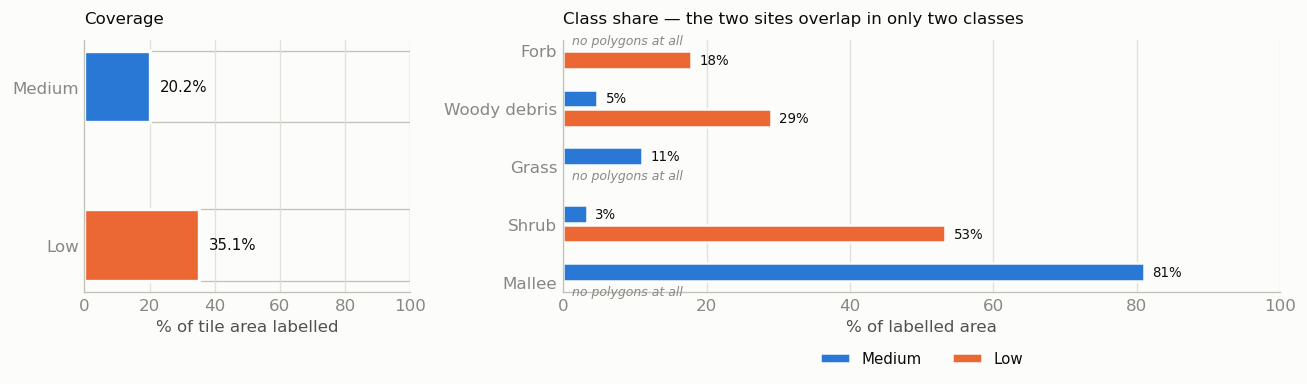

Classes present in both sites: Woody debris, Shrub


In [5]:
names = list(CLASS_LABELS.values())
fig, (ax_cov, ax_mix) = plt.subplots(
    1, 2, figsize=(11, 3.4), gridspec_kw={'width_ratios': [1, 2.2]})

# Left: how much of a tile carries a reference value at all.
y_site = np.arange(len(CONDITIONS))
cov = [DATA[c]['avg']['Labelled area (%)'] for c in CONDITIONS]
ax_cov.barh(y_site, cov, height=0.45, color=[COLOUR[c] for c in CONDITIONS],
            edgecolor=SURFACE, linewidth=2)
ax_cov.barh(y_site, [100] * len(y_site), height=0.45, color='none',
            edgecolor=AXIS, linewidth=0.8, zorder=0)
for i, v in enumerate(cov):
    ax_cov.text(v + 3, i, f'{v:.1f}%', va='center', ha='left', color=INK, fontsize=9)
ax_cov.set_yticks(y_site, CONDITIONS)
ax_cov.invert_yaxis()
ax_cov.set_xlim(0, 100)
ax_cov.set_xlabel('% of tile area labelled')
ax_cov.set_title('Coverage', loc='left', fontsize=10, pad=10)
tidy(ax_cov)

# Right: class share, grouped by site. Hue means the site here and everywhere
# else in this notebook; classes are named on the axis, never coloured.
y = np.arange(len(names))
h = 0.34
for k, cond in enumerate(CONDITIONS):
    vals = [DATA[cond]['avg'].get(f'{n} area (%)') for n in names]
    polys = [DATA[cond]['avg'].get(f'{n} polygons', 0) for n in names]
    pos = y + (k - (len(CONDITIONS) - 1) / 2) * h
    shown = [(p, v) for p, v, n in zip(pos, vals, polys) if n]
    if shown:
        ax_mix.barh([p for p, _ in shown], [v for _, v in shown], height=h * 0.88,
                    color=COLOUR[cond], label=cond, edgecolor=SURFACE, linewidth=1.5)
    for p, v, n in zip(pos, vals, polys):
        if n:
            ax_mix.text(v + 1.2, p, f'{v:.0f}%', va='center', ha='left', color=INK, fontsize=8)
        else:
            ax_mix.text(1.2, p, 'no polygons at all', va='center', ha='left',
                        color=MUTED, fontsize=7.5, style='italic')
ax_mix.set_yticks(y, names)
ax_mix.invert_yaxis()
ax_mix.set_xlim(0, 100)
ax_mix.set_xlabel('% of labelled area')
ax_mix.set_title('Class share — the two sites overlap in only two classes',
                 loc='left', fontsize=10, pad=10)
ax_mix.legend(ncols=2, loc='upper center', bbox_to_anchor=(0.5, -0.18), fontsize=9)
tidy(ax_mix)
plt.tight_layout()
plt.show()

shared = [n for n in names if all(DATA[c]['avg'].get(f'{n} polygons', 0) for c in CONDITIONS)]
print('Classes present in both sites:', ', '.join(shared))

---
## 5. Preservation, as IoU

The labels pass through two lossy transformations before a model sees them, and each gets one
IoU per class. **1.000 is lossless.**

| | Compares | What a shortfall means |
|---|---|---|
| **vector → 1 cm** | polygons rasterised exactly (centroid rule) vs the delivered 1 cm raster | the cost of `all_touched=True`, which dilates each polygon by up to one 1 cm ring, plus resolving overlaps by draw order |
| **1 cm → 5 cm** | majority class of each 5 cm cell's twenty-five 1 cm sub-pixels vs the delivered 5 cm raster | how much the downsample changed the reference the models actually consume |

Nodata counts as a category in the majority rule — otherwise a single labelled 1 cm pixel in
twenty-five would make the whole cell that class, which no downsampling rule would deliver.


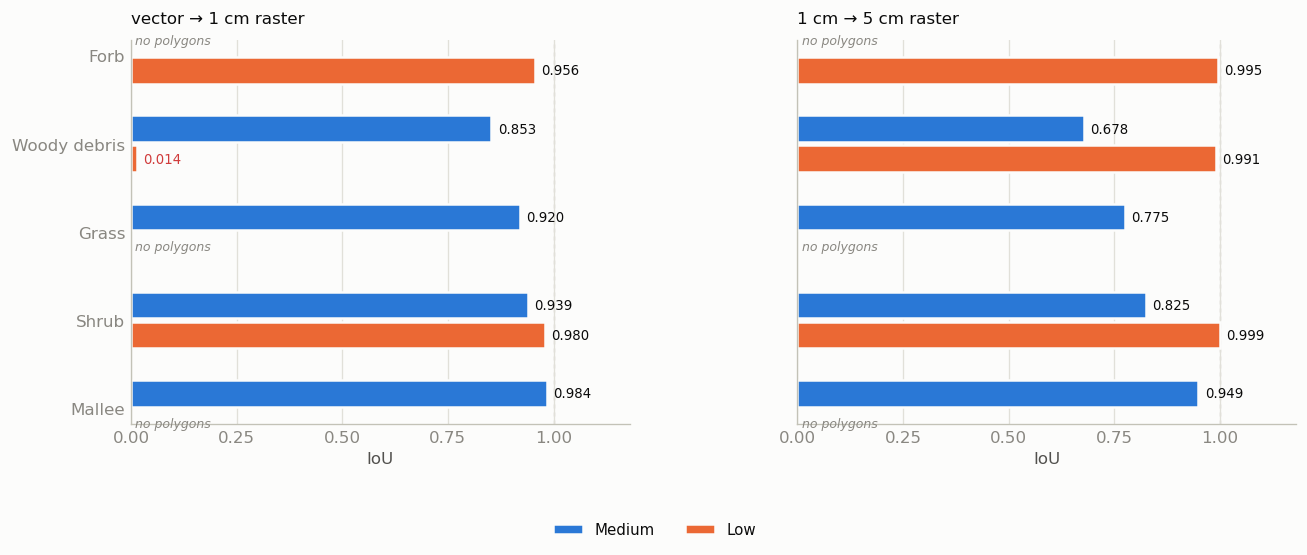

In [6]:
present = [n for n in CLASS_LABELS.values()
            if any(DATA[c]['avg'].get(f'{n} polygons', 0) for c in CONDITIONS)]
panels = [('IoU raster', 'vector → 1 cm raster'), ('IoU 5 cm', '1 cm → 5 cm raster')]

fig, axes = plt.subplots(1, 2, figsize=(11, 0.55 * len(present) + 2.1), sharey=True)
y = np.arange(len(present))
h = 0.34

for ax, (prefix, title) in zip(axes, panels):
    for k, cond in enumerate(CONDITIONS):
        vals = [DATA[cond]['avg'].get(f'{prefix} {n}') for n in present]
        offset = (k - (len(CONDITIONS) - 1) / 2) * h
        pos = y + offset
        finite = [(p, v) for p, v in zip(pos, vals) if pd.notna(v)]
        if finite:
            ax.barh([p for p, _ in finite], [v for _, v in finite], height=h * 0.88,
                    color=COLOUR[cond], label=cond, edgecolor=SURFACE, linewidth=1.5)
        for p, v in zip(pos, vals):
            if pd.isna(v):
                ax.text(0.01, p, 'no polygons', va='center', ha='left',
                        color=MUTED, fontsize=7.5, style='italic')
            else:
                ax.text(v + 0.015, p, f'{v:.3f}', va='center', ha='left',
                        color=INK if v >= 0.5 else '#d03b3b', fontsize=8)
    ax.axvline(1.0, color=AXIS, linewidth=0.8, linestyle=(0, (3, 3)), zorder=0)
    ax.set_xlim(0, 1.18)
    ax.set_xticks([0, 0.25, 0.5, 0.75, 1.0])
    ax.set_title(title, loc='left', fontsize=10, pad=10)
    ax.set_xlabel('IoU')
    tidy(ax)

axes[0].set_yticks(y, present)
axes[0].invert_yaxis()
axes[0].legend(ncols=2, loc='upper center', bbox_to_anchor=(1.05, -0.22), fontsize=9)
plt.tight_layout()
plt.show()

Two numbers do not belong with the others, and they are unrelated to each other.

- **Low site, Woody debris, vector → 1 cm = 0.014.** `all_touched` costs a class a few percent,
  never this. Section 7.2.
- **Medium site, 1 cm → 5 cm = 0.68–0.95** where the low site is 0.99–1.00. Section 7.1.


---
## 6. Why the medium site's 5 cm IoU falls

A 3072 px tile at 1 cm is 30.72 m, and 30.72 / 0.05 = 614.4 is not an integer, so
`gdalwarp -tr 0.05` in `2_3_downsampling_labels.py` cannot land on the 1 cm grid — it snaps to
614 cells and shifts the origin. Because the same call passes `-srcnodata 255`, nearest
resampling onto the shifted grid takes the nearest *valid* source pixel in preference to a nodata
one, so sparse classes are dilated rather than sampled.

The chart is the cause beside the effect: every tile whose grid happens to land on the 1 cm grid
gains no area, and every tile that does not gains ten percent or more.


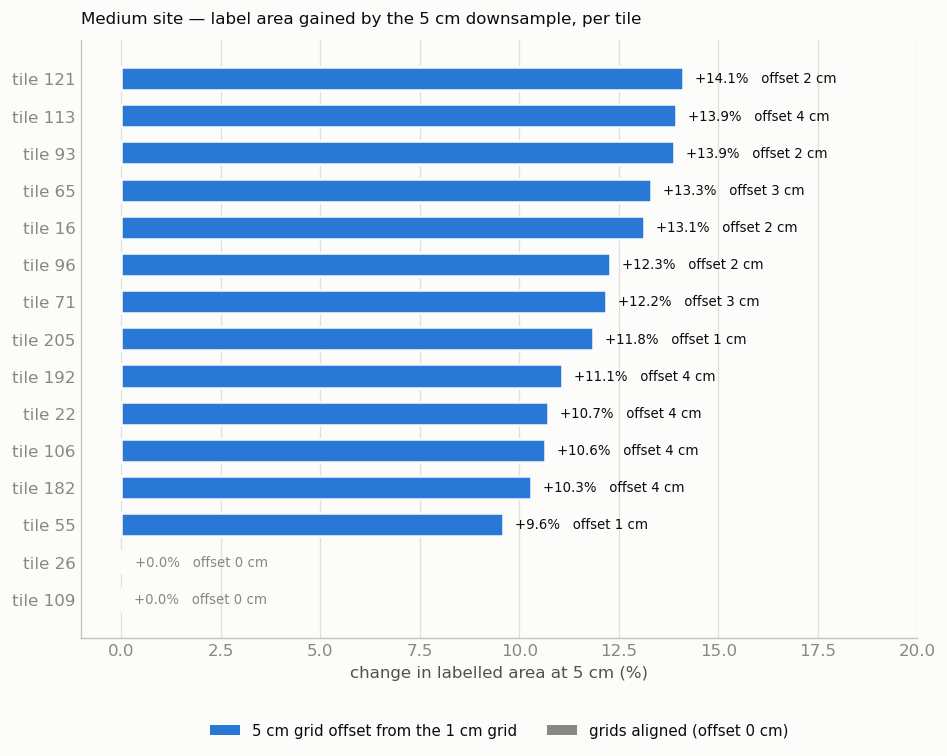

Low site, for contrast: offset 0 cm and +0.12% area change on all 15 tiles.


In [7]:
d = DATA['Medium']
tiles = d['per_tile'].copy()
tiles['offset'] = tiles['5 cm grid offset (cm)']
tiles['change'] = tiles['Labelled area change at 5 cm (%)']
tiles = tiles.sort_values('change')
aligned = tiles['offset'] == 0

fig, ax = plt.subplots(figsize=(8, 0.32 * len(tiles) + 1.6))
y = np.arange(len(tiles))
ax.barh(y, tiles['change'], height=0.62, edgecolor=SURFACE, linewidth=1.5,
        color=[MUTED if a else SERIES[0] for a in aligned])
for i, (chg, off) in enumerate(zip(tiles['change'], tiles['offset'])):
    ax.text(chg + 0.3, i, f'{chg:+.1f}%   offset {off:.0f} cm', va='center', ha='left',
            color=MUTED if off == 0 else INK, fontsize=8)
ax.set_yticks(y, [f'tile {t}' for t in tiles['Tile']])
ax.set_xlim(-1, 20)
ax.set_xlabel('change in labelled area at 5 cm (%)')
ax.set_title('Medium site — label area gained by the 5 cm downsample, per tile',
             loc='left', fontsize=10, pad=10)
handles = [mpl.patches.Patch(facecolor=SERIES[0], label='5 cm grid offset from the 1 cm grid'),
           mpl.patches.Patch(facecolor=MUTED, label='grids aligned (offset 0 cm)')]
ax.legend(handles=handles, ncols=2, loc='upper center', bbox_to_anchor=(0.5, -0.12), fontsize=9)
tidy(ax)
plt.tight_layout()
plt.show()

low = DATA['Low']['per_tile']
print(f"Low site, for contrast: offset {low['5 cm grid offset (cm)'].max():.0f} cm and "
      f"{low['Labelled area change at 5 cm (%)'].abs().max():+.2f}% area change "
      f'on all {len(low)} tiles.')

### The dilation is verified, not inferred

If the extra 5 cm cells came from a *different* version of the 1 cm labels, they would appear
anywhere. If they are resampling dilation, each one must sit within reach of a 1 cm pixel of that
same class. The cell below checks exactly that.


In [8]:
import rasterio

from label_qa import NODATA, VALUE_REMAP

p = DATA['Medium']['paths']
for tile in ['121', '65', '26']:
    with rasterio.open(p['raster'] / f'mask_structure_3072.{tile}.tif') as src:
        fine, ft, fshape = src.read(1), src.transform, src.shape
    with rasterio.open(p['coarse'] / f'mask_structure_3072.{tile}.tif') as src:
        coarse, ct, cshape = src.read(1), src.transform, src.shape
    if coarse.max() > max(CLASS_LABELS):
        inverse = {v: k for k, v in VALUE_REMAP.items()}
        remap = np.full(coarse.shape, NODATA, dtype=np.uint8)
        for cval, sid in inverse.items():
            remap[coarse == cval] = sid
        coarse = remap

    rows_i = np.clip(np.floor((ct.f + (np.arange(cshape[0]) + 0.5) * ct.e - ft.f) / ft.e)
                     .astype(int), 0, fshape[0] - 1)
    cols_i = np.clip(np.floor((ct.c + (np.arange(cshape[1]) + 0.5) * ct.a - ft.c) / ft.a)
                     .astype(int), 0, fshape[1] - 1)
    centre = fine[np.ix_(rows_i, cols_i)]
    extra_r, extra_c = np.nonzero((coarse != NODATA) & (centre == NODATA))

    if extra_r.size == 0:
        print(f'tile {tile:>4}: 0 extra cells — grids aligned, nothing to explain')
        continue
    same_class = 0
    for r, c in zip(extra_r, extra_c):
        r0, c0 = rows_i[r], cols_i[c]
        block = fine[max(r0 - 2, 0):r0 + 3, max(c0 - 2, 0):c0 + 3]
        if np.any(block[block != NODATA] == coarse[r, c]):
            same_class += 1
    print(f'tile {tile:>4}: {extra_r.size:>6,} extra labelled cells, '
          f'{same_class / extra_r.size * 100:5.1f}% have a 1 cm pixel of that exact class '
          f'inside their own 5×5 block')

tile  121:  9,091 extra labelled cells,  99.8% have a 1 cm pixel of that exact class inside their own 5×5 block


tile   65:  7,839 extra labelled cells,  99.4% have a 1 cm pixel of that exact class inside their own 5×5 block
tile   26: 0 extra cells — grids aligned, nothing to explain


---
## 7. Top-of-canopy height against the class scheme

Per polygon, the P95 of `Z_norm` among the LiDAR returns inside it, against the height range its
class implies. LiDAR height was never used to make the 2D labels, so this is a semi-independent
check that the classes mean what the scheme says.

**P95 per polygon, not the median of the column.** A 2D mask is a crown *footprint*, so every
return beneath the plant — ground, litter, understorey — falls inside it. Taking the median over
all of them measures the ground rather than the plant, and reports every tall class as
implausible by construction. Only the medium site has LiDAR matching its tiles.


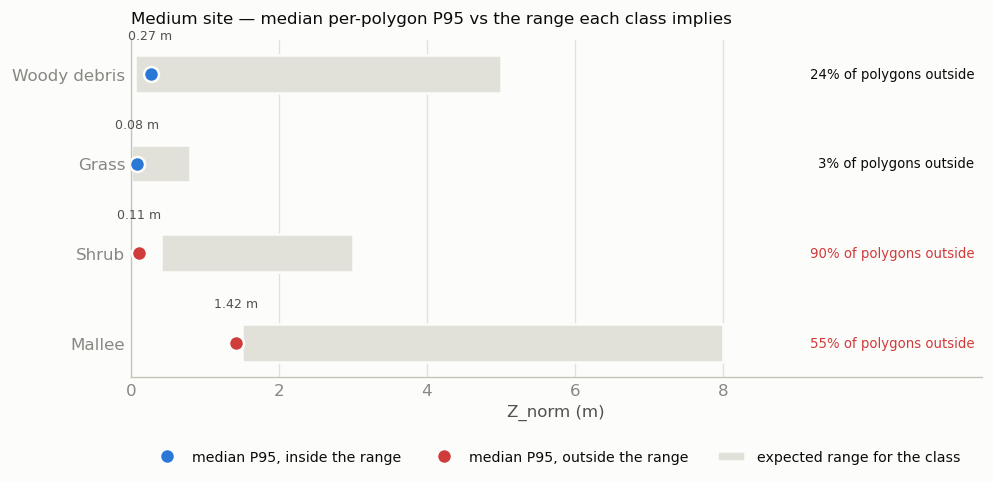

3.4% of polygons carry fewer than 10 returns and are excluded, so this is not a point-density artefact.


In [9]:
a = DATA['Medium']['avg']
classes = [n for n in CLASS_LABELS.values() if pd.notna(a.get(f'P95 Znorm {n} (m)'))]
sid_of = {v: k for k, v in CLASS_LABELS.items()}

fig, ax = plt.subplots(figsize=(8.5, 0.6 * len(classes) + 1.8))
y = np.arange(len(classes))
for i, name in enumerate(classes):
    lo, hi = HEIGHT_RANGES[sid_of[name]]
    ax.barh(i, hi - lo, left=lo, height=0.42, color=GRID, edgecolor=SURFACE, linewidth=1.5,
            zorder=1, label='expected range for the class' if i == 0 else None)
groups = {True: {'y': [], 'x': [], 'colour': SERIES[0], 'label': 'median P95, inside the range'},
          False: {'y': [], 'x': [], 'colour': '#d03b3b', 'label': 'median P95, outside the range'}}
for i, name in enumerate(classes):
    med = a[f'P95 Znorm {name} (m)']
    lo, hi = HEIGHT_RANGES[sid_of[name]]
    inside = lo <= med <= hi
    groups[inside]['y'].append(i)
    groups[inside]['x'].append(med)
    ax.text(11.4, i, f"{a[f'Height outliers {name} (%)']:.0f}% of polygons outside",
            va='center', ha='right', color=INK if inside else '#d03b3b', fontsize=8)
    ax.text(med, i - 0.36, f'{med:.2f} m', va='bottom', ha='center', color=INK_2, fontsize=7.5)
for g in groups.values():
    if g['y']:
        ax.plot(g['x'], g['y'], linestyle='none', marker='o', markersize=9, zorder=3,
                color=g['colour'], markeredgecolor=SURFACE, markeredgewidth=1.5,
                label=g['label'])

ax.set_yticks(y, classes)
ax.invert_yaxis()
ax.set_xlim(0, 11.5)
ax.set_xticks([0, 2, 4, 6, 8])
ax.set_xlabel('Z_norm (m)')
ax.set_title(f'Medium site — median per-polygon P{CANOPY_PERCENTILE} vs the range each class implies',
             loc='left', fontsize=10, pad=10)
ax.legend(ncols=3, loc='upper center', bbox_to_anchor=(0.5, -0.18), fontsize=8.5)
tidy(ax)
plt.tight_layout()
plt.show()

print(f"{a['Polygons with too few returns (%)']:.1f}% of polygons carry fewer than 10 returns "
      'and are excluded, so this is not a point-density artefact.')

---
## 8. Issues logged, per polygon

`<site>_qa_issues.csv` records every problem individually, so a flagged polygon can be opened in
QGIS by tile and row index. Counts rather than a chart: eight categories spanning three orders of
magnitude read better as a table.


In [10]:
counts = pd.DataFrame({c: DATA[c]['issues']['Issue'].value_counts() for c in CONDITIONS})
counts = counts.fillna(0).astype(int)
counts.index.name = 'Issue'
counts['Per tile (Medium)'] = (counts['Medium'] / len(DATA['Medium']['per_tile'])).round(1)
counts['Per tile (Low)'] = (counts['Low'] / len(DATA['Low']['per_tile'])).round(1)
display(counts.sort_values('Medium', ascending=False))
display(DATA['Low']['issues']
        .query("Issue == 'raster_disagrees_with_shapefile'")
        .head(3)[['Tile', 'Issue', 'Details']])

,Medium,Low,Per tile (Medium),Per tile (Low)
Issue,,,,
height_implausible,1262,0,84.1,0.0
too_few_lidar_points,182,0,12.1,0.0
overlap_different_class,128,308,8.5,20.5
invalid_geometry,114,12,7.6,0.8
small_area,85,42,5.7,2.8
overlap_same_class,72,1909,4.8,127.3
grid_misaligned_5cm,13,0,0.9,0.0
raster_disagrees_with_shapefile,0,13,0.0,0.9


,Tile,Issue,Details
166,25,raster_disagrees_with_shapefile,Woody debris: IoU 0.000 between the 1 polygons...
279,30,raster_disagrees_with_shapefile,Woody debris: IoU 0.000 between the 1 polygons...
453,31,raster_disagrees_with_shapefile,Woody debris: IoU 0.000 between the 1 polygons...


---
## 9. Findings to settle before reporting

Each is stated with the measurement that establishes it. Nothing here is asserted without a cell
above or below that produces the number.


### 9.1 The medium site's 5 cm labels are dilated

Established in section 6: 13 of 15 tiles carry a 5 cm grid offset by 1–4 cm from their 1 cm grid,
and those tiles gain 9.6–14.1% labelled area, concentrated in the thinnest classes. The two tiles
whose grids align gain 0.02–0.04%. The extra cells are verified as neighbour dilation, not
different source material.

**Why it matters most.** The models consume the 5 cm labels, so of everything on this page this
has the most direct bearing on the reported results.

**Fix.** Make the 5 cm grid a whole multiple of the 1 cm grid before warping — pad the 1 cm tile
to 3075 px, or pass `-tap` and drop `-srcnodata` so nodata decimates like any other value.


### 9.2 The low site's shapefiles disagree with its rasters

`EXCLUDE_CLASSES` in `2_1_structure_2D_labels.py` contains the typo `'unknowm'`, so `'unknown'`
never matches the exclusion list. The cell below measures what that left behind.


In [11]:
import geopandas as gpd

shp_dir = DATA['Low']['paths']['shp']
rows = []
for shp in sorted(shp_dir.glob('*.shp'), key=lambda p: int(p.stem.split('.')[-1])):
    gdf = gpd.read_file(shp)
    gdf['struct_id'] = gdf['struct_id'].astype(int)
    one = gdf[gdf['struct_id'] == 1]
    unknown = one[one['structure'] == 'unknown']
    rows.append({'Tile': shp.stem.split('.')[-1],
                 'unknown polygons': len(unknown),
                 'their area (m2)': round(float(unknown.geometry.area.sum()), 1),
                 'genuine woody-debris area (m2)':
                     round(float(one[one['structure'] != 'unknown'].geometry.area.sum()), 3)})
u = pd.DataFrame(rows)
tile_area = 30.72 * 30.72
print(f"{u['unknown polygons'].sum()} `unknown` polygons carry struct_id 1 (Woody debris), "
      f"{u['their area (m2)'].sum():.0f} m² in total, "
      f"mean {u['their area (m2)'].sum() / max(u['unknown polygons'].sum(), 1):.0f} m² each "
      f"= {u['their area (m2)'].sum() / max(u['unknown polygons'].sum(), 1) / tile_area * 100:.1f}% of a tile.")
print(f"Genuine woody-debris content at this site: "
      f"{u['genuine woody-debris area (m2)'].sum():.1f} m² in total.")
display(u)

13 `unknown` polygons carry struct_id 1 (Woody debris), 1550 m² in total, mean 119 m² each = 12.6% of a tile.
Genuine woody-debris content at this site: 10.4 m² in total.


,Tile,unknown polygons,their area (m2),genuine woody-debris area (m2)
0,25,1,127.1,0.000
1,30,1,141.8,0.000
2,31,1,94.3,0.000
3,33,1,167.1,4.406
4,39,1,105.2,0.000
5,41,1,118.4,0.000
6,43,1,144.2,0.000
7,48,1,26.1,4.882
8,52,1,62.9,0.000
9,58,1,131.3,0.232


The delivered 1 cm rasters were built *after* those polygons were removed, which is why
`IoU raster Woody debris` is 0.014 rather than the ~0.85 the medium site shows: the shapefiles on
disk are not the version the rasters came from.

**The risk is forward-looking.** The rasters currently in use are correct. But re-running
`2_2_structure_2D_rasterLabels.py` over the shapefiles as they stand would inject a false
Woody-debris region covering an eighth of each affected tile. Fix the typo and re-export the
low-site shapefiles before any step is re-run from them.


### 9.3 The two sites do not share a definition of class 1

Section 4 shows the medium site has IDs 1–4 and no forbs, while the low site has IDs 0, 1 and 3
and no grass or mallee — **only classes 1 and 3 are common to both**, and class 1 is the one
affected by 9.2. The cell below adds the second reason class 1 differs, counted from the
committed step-2 logs.


In [12]:
import re

log_dir = REPO_ROOT / 'phase_3_2D_imagery_prep' / 'step_2_structure_2D_labels' / 'logs'
for log in sorted(log_dir.glob('*.txt')):
    text = log.read_text(encoding='utf-8', errors='replace')
    mapped = sum(int(m) for m in re.findall(r"- litter -> ID 1: (\d+) polygons", text))
    dropped = sum(int(m) for m in re.findall(r"- 'litter': (\d+) polygons", text))
    site = 'low' if '_low_' in log.name else 'medium'
    print(f'{site:>7} site log: litter mapped into ID 1 = {mapped:>4}, '
          f'litter dropped as unrecognised = {dropped:>4}')

    low site log: litter mapped into ID 1 =    1, litter dropped as unrecognised =    0
 medium site log: litter mapped into ID 1 =    0, litter dropped as unrecognised =  752


`'litter': 1` is commented out at line 14 of `2_1_structure_2D_labels.py`. The low-site labels
were produced while it was active, the medium-site labels after it was disabled — so the two runs
did not use the same definition of ID 1.

**The consequence is one-sided.** The low site contained just **1** litter polygon, so folding it
in changed almost nothing there. The medium site contained **752**, all dropped. So ID 1 means
"woody debris, litter excluded" at the medium site and "woody debris plus litter" at the low site,
but only the medium site lost material to the choice. Either re-run one site so both use the same
mapping, or state the exclusion explicitly in the manuscript. This is a decision about label
semantics, so it has deliberately not been changed in code.


### 9.4 The low site has no LiDAR matching its tiles

The height columns are blank for the low site. The cell reports what is actually at its
`--las-dir`, so the reason is visible rather than assumed.


In [13]:
for cond in CONDITIONS:
    las_dir = DATA[cond]['paths']['las']
    tile_ids = sorted(DATA[cond]['per_tile']['Tile'].astype(str), key=int)
    if not las_dir.exists():
        print(f'{cond:>7}: {las_dir} does not exist — 0 of {len(tile_ids)} tiles have LAS')
        continue
    las_ids = sorted({p.stem.split('.')[-1] for p in las_dir.glob('*.las')}, key=int)
    overlap = sorted(set(tile_ids) & set(las_ids), key=int)
    print(f'{cond:>7}: {len(las_ids)} LAS files present. '
          f'label tiles {tile_ids[:4]}…  LAS tiles {(las_ids[:4] or ["none"])}…  '
          f'matching = {len(overlap)}/{len(tile_ids)}')

 Medium: 15 LAS files present. label tiles ['16', '22', '26', '55']…  LAS tiles ['16', '22', '26', '55']…  matching = 15/15
    Low: /tmp/wsl_drive_d/paper2/data/calperumResearch/site1_1_DD0011/lidar/clipped/raster/z_norm/csf does not exist — 0 of 15 tiles have LAS


---
## 10. What this cannot measure — reproducibility

Nothing above answers *"would a second annotator draw the same thing?"*. That is the one number
a reviewer is most likely to want, and it needs a second, blind delineation compared with
`compare_reannotation.py`.

**Sampling design.** Draw 3 tiles per site at random, stratified so each site's dominant classes
appear, and record the seed. Re-digitise from the same 1 cm orthomosaic blind to the originals —
a second annotator if available, otherwise the same annotator after a gap long enough that the
first delineation is not recalled. Save to a parallel directory with identical filenames.

**Two scopes are reported.** The all-cells number mixes *delineation* disagreement (where a crown
edge falls) with *classification* disagreement (what the plant is). The interior-only number
excludes a 5-cell buffer around class boundaries and isolates the second — the one that limits
achievable model accuracy. Reporting both pre-empts the objection that a mediocre OA is edge noise.

The cell below is a no-op until the repeat annotation exists.


In [14]:
for cond in CONDITIONS:
    d = DATA[cond]
    redo = d['paths']['mask'] / f"{d['shp_subdir']}_reannotation"
    if not redo.exists() or not list(redo.glob('*.shp')):
        print(f'{cond:>7}: no repeat annotation at {redo} — skipping')
        continue
    cmd = [sys.executable, str(STEP_DIR / 'compare_reannotation.py'),
           '--shp-dir-a', str(d['paths']['shp']), '--shp-dir-b', str(redo),
           '--raster-dir', str(d['paths']['raster']),
           '--site-condition', d['condition'], '--output-dir', str(d['paths']['out'])]
    result = subprocess.run(cmd, text=True, capture_output=True)
    if result.returncode != 0:
        print(result.stderr[-2000:], file=sys.stderr)
    else:
        display(pd.read_csv(d['paths']['out'] / 'r1_reannotation_agreement_average.csv'))

 Medium: no repeat annotation at /tmp/wsl_drive_d/paper2/data/calperumResearch/site1_1_DD0001/imagery/inputs/masks/tiles_3072/raw/structure_class/annotations_shp_reannotation — skipping
    Low: no repeat annotation at /tmp/wsl_drive_d/paper2/data/calperumResearch/site1_1_DD0011/imagery/inputs/masks/tiles_3072/raw/structure_class/annotation_shp_reannotation — skipping
